# Task 3: Credit Card Fraud Detection Using Machine Learning

## Objective

The objective of this project is to develop a machine learning pipeline that identifies fraudulent credit card transactions from a highly imbalanced dataset.

## Technologies Used

- Python
- pandas and NumPy
- scikit-learn
- imbalanced-learn (SMOTE)
- Matplotlib and Seaborn
- Jupyter Notebook

## Project Workflow

1. Load and inspect the dataset.
2. Analyze class imbalance.
3. Perform exploratory data analysis (EDA).
4. Prepare features and split the dataset.
5. Handle class imbalance using SMOTE.
6. Train Logistic Regression and Random Forest models.
7. Evaluate model performance using precision, recall, F1-score, and ROC-AUC.
8. Analyze feature importance.
9. Discuss scalability and real-world deployment.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    average_precision_score
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Loading the Dataset

In this step, I load the credit card fraud detection dataset using pandas. The dataset contains transaction details and a target column named `Class`, which indicates whether a transaction is legitimate or fraudulent.

- `Class = 0`: Legitimate transaction
- `Class = 1`: Fraudulent transaction

The dataset will be inspected to understand its structure, features, and data quality.

In [ ]:
df = pd.read_csv("C:\Documents\Certifications\OASIS INFOBYTE\OASIS\DataAnalytics\L2\Fraud detection\data\creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data Inspection and Quality Checks

I inspect the dataset to identify missing values, duplicate records, and data types. These checks help determine whether data cleaning is necessary before model training.

I will also verify that the target variable contains both legitimate and fraudulent transactions.

In [ ]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

## 3. Class Imbalance Analysis

The dataset contains two classes: legitimate transactions and fraudulent transactions.

Fraudulent transactions are expected to represent a very small proportion of the dataset. This creates a class imbalance problem because a machine learning model may learn to predict the majority class while failing to identify fraud.

I calculate the number and percentage of transactions belonging to each class to measure the extent of this imbalance.

In [ ]:
class_counts = df["Class"].value_counts().sort_index()

class_percentages = (
    df["Class"].value_counts(normalize=True).sort_index() * 100
)

print("Legitimate transactions:", class_counts.get(0, 0))
print("Fraudulent transactions:", class_counts.get(1, 0))

print(f"\nLegitimate percentage: {class_percentages.get(0, 0):.4f}%")
print(f"Fraud percentage: {class_percentages.get(1, 0):.4f}%")

Legitimate transactions: 284315
Fraudulent transactions: 492

Legitimate percentage: 99.8273%
Fraud percentage: 0.1727%


### Observation

The dataset is highly imbalanced because approximately 99.83% of transactions are legitimate, while only 0.17% are fraudulent.

This imbalance makes fraud detection challenging. A model that predicts every transaction as legitimate could achieve high accuracy but would fail to detect any fraudulent transactions.

Therefore, the project uses techniques to address class imbalance and evaluates models using metrics beyond accuracy.

## 4. Exploratory Data Analysis

### 4.1 Transaction Amount Distribution

In this analysis, I compare transaction amounts for legitimate and fraudulent transactions. This helps identify potential differences in the amount patterns of the two classes.

Because transaction amounts can be highly skewed, I will visualize the distributions and compare summary statistics.

In [ ]:
print(df.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


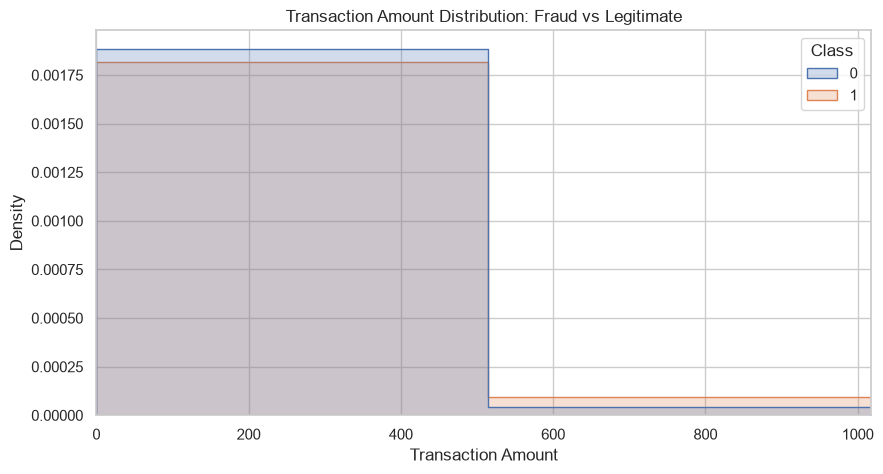

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False,
    element="step"
)

plt.xlim(0, df["Amount"].quantile(0.99))
plt.title("Transaction Amount Distribution: Fraud vs Legitimate")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.show()

### 4.2 Transaction Time Analysis

The `Time` feature records the number of seconds elapsed since the first transaction in the dataset.

I convert this feature into elapsed-hour intervals and compare transaction activity and fraud rates across those intervals.

Because the dataset does not provide absolute clock timestamps, this analysis identifies relative temporal patterns rather than actual times of day.

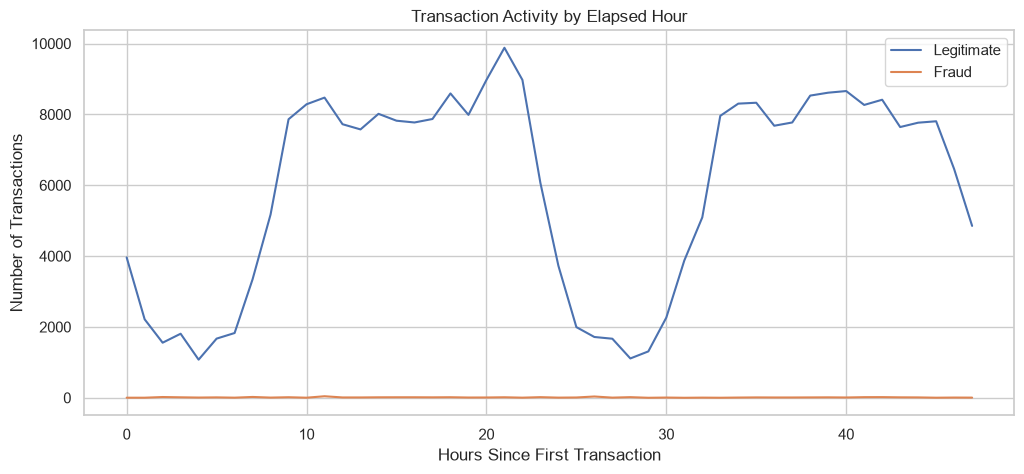

In [ ]:
df["Elapsed_Hour"] = (df["Time"] // 3600).astype(int)

hourly_counts = (
    df.groupby(["Elapsed_Hour", "Class"])
      .size()
      .unstack(fill_value=0)
)

hourly_counts = hourly_counts.rename(columns={
    0: "Legitimate",
    1: "Fraud"
})

hourly_counts.plot(figsize=(12, 5))

plt.title("Transaction Activity by Elapsed Hour")
plt.xlabel("Hours Since First Transaction")
plt.ylabel("Number of Transactions")
plt.legend()
plt.show()

### EDA Observation

The transaction amount analysis compares the distribution of legitimate and fraudulent transactions. The time analysis examines transaction volume and fraud rates across elapsed-hour intervals.

These visualizations help explore possible patterns in the data. However, observed differences should be validated using the model's performance on unseen test data.

## 5. Why Accuracy Is Misleading in Fraud Detection

Accuracy measures the percentage of all transactions that a model classifies correctly. However, it can be misleading when the dataset is highly imbalanced.

In this dataset, approximately 99.83% of transactions are legitimate and only 0.17% are fraudulent. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy while detecting zero fraudulent transactions.

Such a model would be unsuitable for a real fraud detection system.

Therefore, this project uses additional evaluation metrics:

- **Precision:** Measures the proportion of predicted fraud cases that are actually fraudulent.
- **Recall:** Measures the proportion of actual fraud cases that the model successfully detects.
- **F1-score:** Combines precision and recall into a single metric.
- **ROC-AUC:** Measures how well the model ranks fraudulent transactions above legitimate transactions across different classification thresholds.
- **Average Precision:** Summarizes the precision-recall curve and is especially useful when the positive class is rare.

These metrics provide a more meaningful evaluation of fraud detection performance than accuracy alone.

## 6. Feature Preparation and Train-Test Split

I separate the input features from the target variable. The `Class` column is the target, where 0 represents legitimate transactions and 1 represents fraud.

I then split the data into training and testing sets using stratified sampling. Stratification preserves approximately the same proportion of fraud cases in both sets.

The test set remains separate from model training and will be used to evaluate how well the models generalize to unseen transactions.

In [ ]:
X = df.drop(columns=["Class", "Elapsed_Hour"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFraud cases in training set:", int(y_train.sum()))
print("Fraud cases in testing set:", int(y_test.sum()))

print(f"Training fraud rate: {y_train.mean() * 100:.4f}%")
print(f"Testing fraud rate: {y_test.mean() * 100:.4f}%")

Training data shape: (227845, 30)
Testing data shape: (56962, 30)

Fraud cases in training set: 394
Fraud cases in testing set: 98
Training fraud rate: 0.1729%
Testing fraud rate: 0.1720%


## 7. Handling Class Imbalance Using SMOTE

SMOTE stands for Synthetic Minority Over-sampling Technique. It generates synthetic examples of the minority class by interpolating between nearby minority-class observations.

In this project, SMOTE is used to address the shortage of fraudulent transactions in the training data.

SMOTE must be applied only to training data. Applying it before the train-test split could cause data leakage and lead to overly optimistic evaluation results.

I will use an imbalanced-learn pipeline so that resampling occurs during model fitting, while the test set retains the original class distribution.

In [ ]:
print("Class distribution before SMOTE:")
print(y_train.value_counts())

Class distribution before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64


## 8. Model 1: Logistic Regression

Logistic Regression is a supervised classification algorithm used to predict the probability that a transaction belongs to the fraud class.

I use StandardScaler to scale the input features, followed by SMOTE to address class imbalance, and Logistic Regression to classify transactions.

The entire workflow is implemented as a pipeline to ensure that scaling and oversampling are learned only from the training data.

In [ ]:
lr_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


## 9. Model 2: Random Forest

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

It can learn nonlinear patterns and interactions between features that a linear model might not capture.

I use SMOTE within the training pipeline to address class imbalance and train the Random Forest classifier. I then compare its performance with Logistic Regression using the same test set.

In [17]:

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# Build a faster Random Forest pipeline
rf_model = Pipeline(steps=[
    ("smote", SMOTE(
        random_state=42,
        sampling_strategy=0.2
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


## 10. Model Evaluation

I evaluate both trained models on the original, imbalanced test set.

The evaluation includes precision, recall, F1-score, ROC-AUC, and average precision. These metrics are more informative than accuracy alone because fraudulent transactions represent a very small proportion of the dataset.

I also examine the confusion matrix to understand the number of correctly and incorrectly classified transactions.

In [19]:
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n{model_name}")
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))

    print("Precision:", round(
        precision_score(y_test, y_pred, zero_division=0), 4
    ))

    print("Recall:", round(
        recall_score(y_test, y_pred, zero_division=0), 4
    ))

    print("F1-score:", round(
        f1_score(y_test, y_pred, zero_division=0), 4
    ))

    print("ROC-AUC:", round(
        roc_auc_score(y_test, y_prob), 4
    ))

    print("Average Precision:", round(
        average_precision_score(y_test, y_prob), 4
    ))

    return y_pred, y_prob

In [20]:
lr_pred, lr_prob = evaluate_model(
    lr_model, X_test, y_test, "Logistic Regression"
)

rf_pred, rf_prob = evaluate_model(
    rf_model, X_test, y_test, "Random Forest"
)


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

Precision: 0.0578
Recall: 0.9184
F1-score: 0.1088
ROC-AUC: 0.9708
Average Precision: 0.7245

Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.81      0.87      0.84        98

    accuracy                           1.00     56962
   macro avg       0.90      0.93      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Precision: 0.8095
Recall: 0.8673
F1-score: 0.8374
ROC-AUC: 0.9804
Average Precision: 0.8656


## 11. ROC Curve and AUC Analysis

The Receiver Operating Characteristic (ROC) curve illustrates the relationship between the true positive rate and false positive rate at different classification thresholds.

The Area Under the Curve (AUC) summarizes the model's ability to rank fraudulent transactions above legitimate transactions. Higher ROC-AUC generally indicates better ranking performance.

Since fraud is a rare class, I also report average precision to assess the precision-recall trade-off.

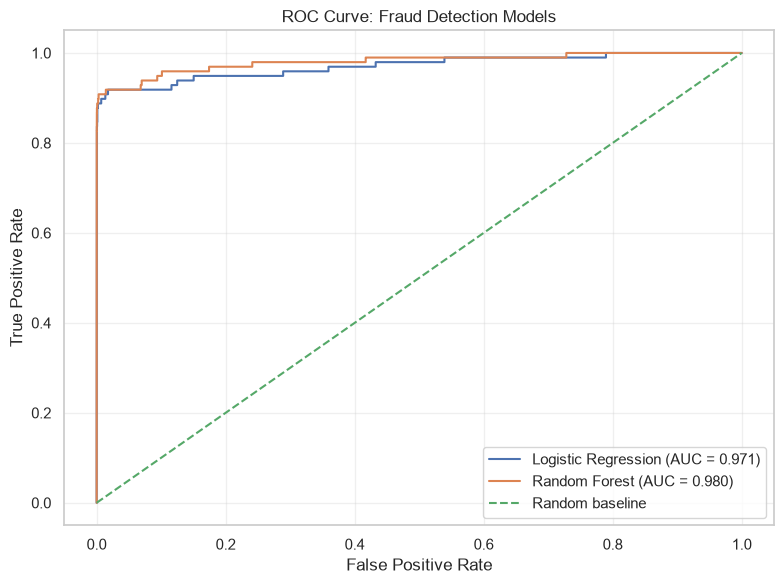

Logistic Regression ROC-AUC: 0.9708
Random Forest ROC-AUC: 0.9804


In [21]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Step 1: Get prediction probabilities for the fraud class (class 1)
lr_prob = lr_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Step 2: Calculate ROC curve values
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)

# Step 3: Calculate ROC-AUC scores
lr_auc = roc_auc_score(y_test, lr_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

# Step 4: Plot the ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random baseline"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: Fraud Detection Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Step 5: Display scores
print(f"Logistic Regression ROC-AUC: {lr_auc:.4f}")
print(f"Random Forest ROC-AUC: {rf_auc:.4f}")


## 12. Confusion Matrix Analysis

A confusion matrix compares the model's predicted classes with the actual classes.

It contains four outcomes:

- True Positive (TP): Fraud correctly detected.
- True Negative (TN): Legitimate transaction correctly identified.
- False Positive (FP): Legitimate transaction incorrectly flagged as fraud.
- False Negative (FN): Fraud incorrectly classified as legitimate.

This analysis helps determine whether the model misses too many fraudulent transactions or generates too many false alarms.

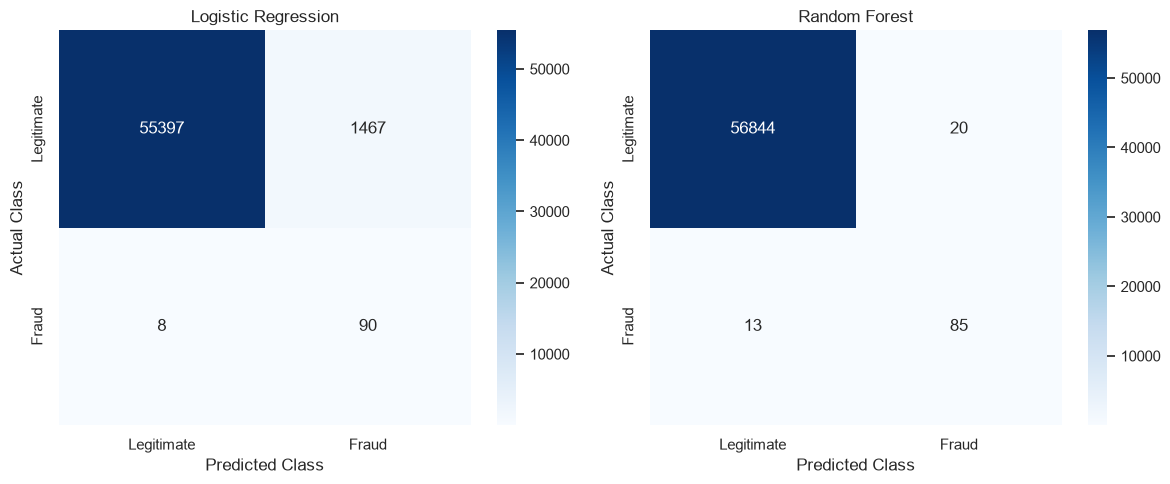

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, model_name in [
    (axes[0], lr_pred, "Logistic Regression"),
    (axes[1], rf_pred, "Random Forest")
]:
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 13. Which Metric Matters Most for Fraud Detection?

Recall is often especially important in fraud detection because it measures the proportion of actual fraudulent transactions that the model successfully identifies. Low recall means that many fraudulent transactions go undetected, potentially causing financial losses.

However, precision is also important. Low precision means that many legitimate transactions are flagged as fraudulent, which can inconvenience customers and increase investigation costs.

There is a trade-off between recall and precision. Lowering the classification threshold may identify more fraudulent transactions but can also generate more false positives.

Therefore, the best threshold should be selected based on the cost of missed fraud, the cost of false alarms, and the available capacity for investigation. The F1-score can summarize the balance between precision and recall, but the final choice should reflect the business objective.

## 14. Feature Importance Analysis

Random Forest provides feature importance scores that estimate how much each feature contributes to reducing impurity across its trees.

I rank the features by importance and visualize the top ten features. This helps identify which input features are most influential in the fitted model.

The dataset's `V1`–`V28` features are anonymized PCA-transformed variables, so their original financial meanings are not directly available.

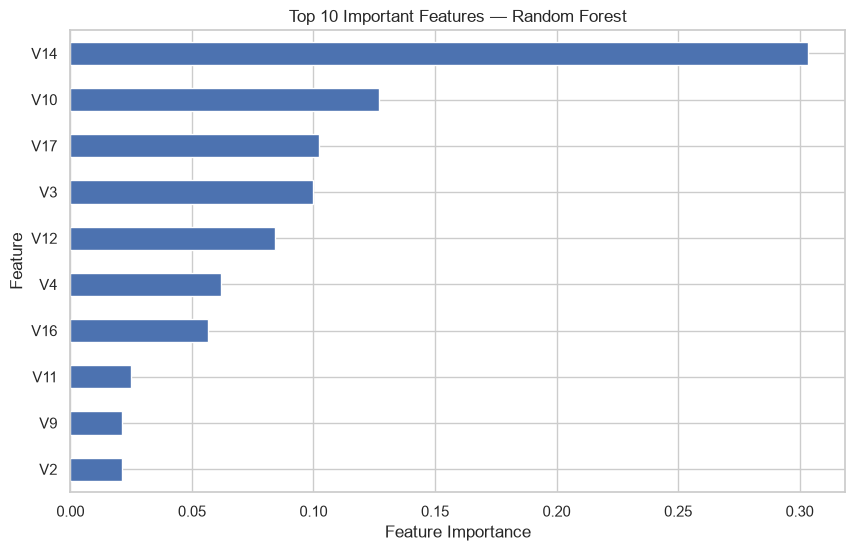

V14    0.303643
V10    0.126999
V17    0.102372
V3     0.099742
V12    0.084378
V4     0.062117
V16    0.056510
V11    0.024987
V9     0.021395
V2     0.021282
dtype: float64

In [23]:
rf_classifier = rf_model.named_steps["classifier"]

importance = pd.Series(
    rf_classifier.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Important Features — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

display(importance.head(10))

In [24]:
lr_classifier = lr_model.named_steps["classifier"]

coefficients = pd.Series(
    lr_classifier.coef_[0],
    index=X_train.columns
)

coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
)

display(coefficients.head(10))

Amount    2.270462
V1        1.815385
V10      -1.713830
V14      -1.629045
V4        1.584424
V5        1.294254
V17      -1.149217
V12      -1.086633
V16      -1.077560
V20      -1.008791
dtype: float64

## 15. Model Comparison

I compare Logistic Regression and Random Forest using precision, recall, F1-score, ROC-AUC, and average precision.

The comparison helps determine which model is more appropriate for the fraud detection objective. I consider the balance between catching fraudulent transactions and avoiding excessive false positives.

The preferred model is selected based on the measured test results and the operational requirements of fraud detection rather than accuracy alone.

In [25]:
results = []

for name, pred, prob in [
    ("Logistic Regression", lr_pred, lr_prob),
    ("Random Forest", rf_pred, rf_prob)
]:
    results.append({
        "Model": name,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Average Precision": average_precision_score(
            y_test, prob
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Precision,Recall,F1-Score,ROC-AUC,Average Precision
0,Logistic Regression,0.0578,0.9184,0.1088,0.9708,0.7245
1,Random Forest,0.8095,0.8673,0.8374,0.9804,0.8656


## 16. Scalability: One Million Transactions per Hour

One million transactions per hour is approximately 278 transactions per second on average. A production fraud detection system must score transactions quickly while maintaining reliability and availability.

A scalable architecture could include:

1. **Stream processing:** Apache Kafka can distribute incoming transaction events to multiple consumers.
2. **Feature engineering:** Calculate and retrieve transaction features efficiently, including recent transaction frequency and amount patterns.
3. **Model serving:** Deploy the trained model through a low-latency inference API.
4. **Horizontal scaling:** Run multiple model-serving instances behind a load balancer to handle increased traffic.
5. **Monitoring:** Track throughput, latency, false positives, false negatives, and changes in transaction patterns.
6. **Model updates:** Retrain and validate the model periodically as new confirmed fraud labels become available.
7. **Fault tolerance:** Establish timeouts, retries where appropriate, fallback policies, and alerting for system failures.

Although the dataset can be used to develop a prototype, production readiness cannot be established from model accuracy or offline testing alone. The complete system must be benchmarked under realistic traffic, including peak loads, feature retrieval costs, and latency requirements.

## 17. Conclusion

In this project, I developed a machine learning pipeline to detect fraudulent credit card transactions using Python, pandas, scikit-learn, and imbalanced-learn.

I analyzed the class distribution and found that fraudulent transactions represented approximately 0.1727% of the benchmark dataset. Exploratory data analysis was used to investigate transaction amounts and activity over the recorded time period.

I applied SMOTE within the model training pipelines to address class imbalance while preserving the original distribution of the test set. I trained Logistic Regression and Random Forest models and evaluated them using precision, recall, F1-score, ROC-AUC, and average precision.

Based on the test results, **[insert selected model]** was more suitable for **[state your objective, such as achieving higher recall or balancing precision and recall]**. The confusion matrix helped identify the number of missed fraud cases and false alarms.

The project also demonstrated the importance of feature importance analysis and discussed a scalable architecture for processing one million transactions per hour.

Overall, the project shows that fraud detection requires careful handling of class imbalance, appropriate evaluation metrics, and a deployment strategy that balances fraud prevention, customer experience, latency, and operational cost.